In [52]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import TimeSeriesSplit
import json
from itertools import product
from tensorflow.keras.layers import Input, LSTM, Attention, Dense
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from tensorflow.keras.metrics import RootMeanSquaredError
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

from numpy import sort
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import shap
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score, average_precision_score


In [53]:
#FOR CSV
# re opening the Mflare instances time series collection files
#dataframe
cleanedfulldata_reloaded = pd.read_csv("/kaggle/input/cleanedfulldata-withrand-25col/cleanedfulldata_withrand_25COL.csv")
#converting the json formatted strings into python list (.loads) into a numpy array (.array) and finally does it on all elements in the input/output (.apply)
#xflareinstances_reloaded["input"/"output"] is a pandas series
inputdata = cleanedfulldata_reloaded["input"].apply(lambda x: np.array(json.loads(x)))
outputdata = cleanedfulldata_reloaded["output"]

#stack into a 3d array for lstm use
#.to_numpy makes it a 1d array array([array[], array[], ...]), N separate arrays of (L, F)
#.stack makes it (N, L, F), adds another dimension into a 3d array!!!!
X = np.stack(inputdata.to_numpy())
Y = np.stack(outputdata.to_numpy()) 

print(X.shape)
print(Y.shape)

(7976, 15, 27)
(7976,)


In [54]:
#removing xr_qual and is_tmfi
#ONLY RUN THIS ONCE OTHERWISE IT WILL KEEP ON DELETING
#removing last two elements 
X = X[:, :, :-2]
X.shape

(7976, 15, 25)

In [55]:
#shuffle the data 
shuffled_indices = np.random.permutation(len(X))

# 3. Apply the *same* indices to both datasets
X = X[shuffled_indices]
Y = Y[shuffled_indices]

In [56]:
# Chronological split (no shuffling for time series)
split = int(0.60 * len(X))
X_train, Y_train = X[:split], Y[:split]
X_val,   Y_val   = X[split:], Y[split:]
X_val.shape

(3191, 15, 25)

In [57]:
idx = np.where((X_val[:, 0, -1] == 0.00001962) & (X_val[:, 1, -1] == 0.000015993) & (X_val[:, 2, -1] == 0.000011696))[0]
idx

array([], dtype=int64)

In [58]:
idx = np.where((X_val[:, 0, -1] == 0.0000021336) & (Y_val == 1))[0]
idx

array([], dtype=int64)

In [59]:
idx = np.where(Y_val == 0)[0]
idx

array([   0,    1,    2, ..., 3185, 3186, 3187])

In [60]:
L = 15
F = 25

In [61]:
print("TRAINING --------------------------------")
print("number of positive samples: " + str(len(Y_train[Y_train == 2])+len(Y_train[Y_train == 1])))     
print("number of m samples: " + str(len(Y_train[Y_train == 1])))
print("number of x samples: " + str(len(Y_train[Y_train == 2])))     
print("number of nonflaring samples: " + str(len(Y_train[Y_train == 0])))

print("TESTING --------------------------------")
print("number of positive samples: " + str(len(Y_val[Y_val == 2])+len(Y_val[Y_val == 1])))     
print("number of m samples: " + str(len(Y_val[Y_val == 1])))
print("number of x samples: " + str(len(Y_val[Y_val == 2])))     
print("number of nonflaring samples: " + str(len(Y_val[Y_val == 0])))

TRAINING --------------------------------
number of positive samples: 1855
number of m samples: 1740
number of x samples: 115
number of nonflaring samples: 2930
TESTING --------------------------------
number of positive samples: 1208
number of m samples: 1142
number of x samples: 66
number of nonflaring samples: 1983


In [62]:
len(X_train[np.isnan(X_train)])
#number of NAN!! should be 0

0

In [63]:
#NEW LOG SCALER
#clip replaces all the negative values with 0, fine because no negatives
#computes log(1 + z), handles zeros and small values better than plain log
#same shape is maintained
X_log = np.log1p(np.clip(X, 0, None))

# 2. Scale features
#creating a scaler on the training section of the data -> using the logged version
#reshapes the dataset to be (rows*time steps, feature) cause time series doesn't work on scaling
x_scaler = StandardScaler().fit(X_log[:split].reshape(-1, F))

#implementing this scaler onto both the training and validation datasets
#avoids leakage, only has information on the training sets
#the dataset is re-reshaped into its original (n, l, f) form after it is scaled
X_train_s = x_scaler.transform(X_log[:split].reshape(-1, F)).reshape(X_train.shape)
X_val_s   = x_scaler.transform(X_log[split:].reshape(-1, F)).reshape(X_val.shape)

#DO NOT SCALE THE Y VALUES! THEY ARE BINARY

**---------- SIMPLE XGBOOST START ----------**

In [64]:
# (N,L,F) -> (N,F*5)
def lstm_to_xgb_features(X):
    mean = X.mean(axis=1)
    std  = X.std(axis=1)
    last = X[:, -1, :]
    minv = X.min(axis=1)
    maxv = X.max(axis=1)

    return np.concatenate([mean, std, last, minv, maxv], axis=1)


In [65]:
X_train_xgb = lstm_to_xgb_features(X_train_s)
X_val_xgb   = lstm_to_xgb_features(X_val_s)

print(X_train_xgb.shape)

(4785, 125)


In [66]:
model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

model.fit(X_train_xgb, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_class=3, num_parallel_tree=None, ...)

In [67]:
y_pred = model.predict(X_val_xgb)

acc = accuracy_score(Y_val, y_pred)

print("Accuracy:", acc)
print(classification_report(Y_val, y_pred))
macro_precision = precision_score(Y_val, y_pred, average='macro')
macro_recall = recall_score(Y_val, y_pred, average='macro')
macro_score = f1_score(Y_val, y_pred, average='macro')
print("macropres:", macro_precision)
print("macrorec:", macro_recall)

print(classification_report(Y_val, y_pred))
print(confusion_matrix(Y_val, y_pred))

Accuracy: 0.9793168285803823
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1983
           1       0.96      0.98      0.97      1142
           2       0.90      0.79      0.84        66

    accuracy                           0.98      3191
   macro avg       0.95      0.92      0.93      3191
weighted avg       0.98      0.98      0.98      3191

macropres: 0.9499194224702331
macrorec: 0.9181999524750916
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1983
           1       0.96      0.98      0.97      1142
           2       0.90      0.79      0.84        66

    accuracy                           0.98      3191
   macro avg       0.95      0.92      0.93      3191
weighted avg       0.98      0.98      0.98      3191

[[1950   33    0]
 [  13 1123    6]
 [   0   14   52]]


In [68]:
def plot_confusion_matrix(
    y_true,
    y_pred,
    class_names,
    normalize=True,
    title="Confusion Matrix",
    cmap="Blues"
):
    """
    Professional confusion matrix visualization.
    
    Parameters
    ----------
    y_true : array-like
        Ground truth labels
    y_pred : array-like
        Predicted labels
    class_names : list of str
        Names of classes in order [0, 1, 2, ...]
    normalize : bool
        Whether to normalize by true class counts
    """

    cm = confusion_matrix(y_true, y_pred)

    if normalize:
        cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
    else:
        cm_norm = cm

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm_norm, interpolation="nearest", cmap=cmap)

    # Colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Fraction" if normalize else "Count", rotation=90)

    # Axis labels
    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        ylabel="True Label",
        xlabel="Predicted Label",
        title=title
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    # Annotate cells
    fmt = ".2f" if normalize else "d"
    thresh = cm_norm.max() / 2.0

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i,
                f"{cm_norm[i, j]:{fmt}}\n({cm[i, j]})" if normalize else f"{cm[i, j]}",
                ha="center",
                va="center",
                color="white" if cm_norm[i, j] > thresh else "black",
                fontsize=11
            )

    ax.grid(False)
    fig.tight_layout()
    plt.show()

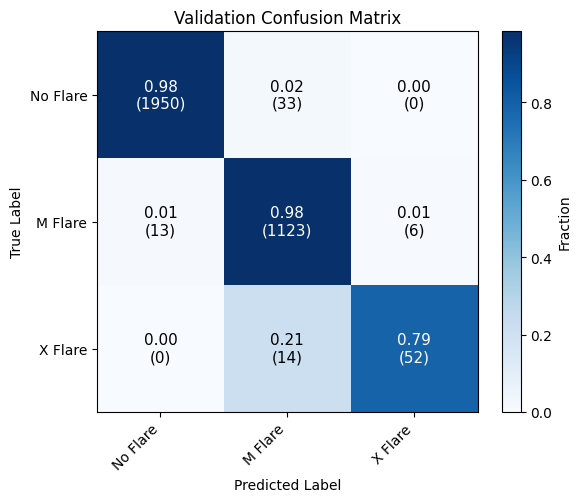

In [69]:
class_names = ["No Flare", "M Flare", "X Flare"]

plot_confusion_matrix(
    y_true=Y_val,
    y_pred=y_pred,
    class_names=class_names,
    normalize=True,
    title="Validation Confusion Matrix"
)

**feature selection for xgboost ------**

In [70]:
basicfeature_names = ['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'TOTFZ', 'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45', 'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH', 'MEANJZH', 'TOTFY', 'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE',  "XR_MAX"]
feature_names = []

stats = ["mean", "std", "last", "min", "max"]
for f in range(F):
    for s in stats:
        
        feature_names.append(f"{s}_"+basicfeature_names[f])
        

In [71]:
booster = model.get_booster()
importance = booster.get_score(importance_type="gain")

D = X_train_xgb.shape[1]
gains = np.array([importance.get(f"f{i}", 0.0) for i in range(D)])
rank_gain = pd.Series(gains, index=feature_names).sort_values(ascending=False)

top_idx = np.argsort(gains)[::-1]
top_idx

array([100,  50,   0,  75, 102,  98,  53,   2,   5,  97,  54,   3,   8,
       115, 104,  79,  96,  95, 123,   4,   6,  86,  23,  15,  73,  52,
        77,  13,  24,  80,  21,  42,  61,  68,  20,  78,  28,  76,  18,
        41,  16,  48,  55, 105,  26,  27,  39, 112, 118,  47,  81,  30,
         1,  88, 106,  63,  62,  70,  33,  66,  14,  83, 108,  45,  99,
        40, 103,  25,  46,  17,  29, 117,  89, 101,  43,  91,  10,  72,
        87,  56, 113,  69,  22,  31,  93,  49,  74, 124,  58, 122,  94,
        90,  12,  19,  35, 116, 110, 114,  65,  36,  38,  44,  71,  67,
        37,  64,  11, 121, 120,  51, 111,  60,  85,  92, 119,  32,  34,
       107,   7,   9,  57,  84,  59,  82, 109])

In [72]:
shaprank = []
for i in top_idx:
    print(feature_names[i], gains[i])
    shaprank.append(feature_names[i])

shaprank
    

mean_TOTFX 141.02210998535156
mean_MEANSHR 123.2502212524414
mean_TOTUSJH 48.928062438964844
mean_MEANGBH 8.59943962097168
last_TOTFX 7.94549560546875
min_MEANALP 7.915567398071289
min_MEANSHR 3.8464372158050537
last_TOTUSJH 3.3512628078460693
mean_TOTBSQ 2.9953081607818604
last_MEANALP 2.754077434539795
max_MEANSHR 2.753026247024536
min_TOTUSJH 2.6927788257598877
min_TOTBSQ 2.6492066383361816
mean_R_VALUE 2.5439584255218506
max_TOTFX 2.382871150970459
max_MEANGBH 2.3632280826568604
std_MEANALP 2.343886613845825
mean_MEANALP 2.2215049266815186
min_XR_MAX 2.152621030807495
max_TOTUSJH 2.1349453926086426
std_TOTBSQ 2.1028013229370117
std_TOTFY 2.100196599960327
min_ABSNJZH 2.000955104827881
mean_TOTUSJZ 1.974355697631836
min_MEANGBZ 1.9625517129898071
last_MEANSHR 1.9365125894546509
last_MEANGBH 1.9334551095962524
min_TOTPOT 1.8148835897445679
max_ABSNJZH 1.7846746444702148
mean_MEANJZH 1.7831482887268066
std_ABSNJZH 1.745069980621338
last_MEANPOT 1.7324962615966797
std_MEANGAM 1.7312300

['mean_TOTFX',
 'mean_MEANSHR',
 'mean_TOTUSJH',
 'mean_MEANGBH',
 'last_TOTFX',
 'min_MEANALP',
 'min_MEANSHR',
 'last_TOTUSJH',
 'mean_TOTBSQ',
 'last_MEANALP',
 'max_MEANSHR',
 'min_TOTUSJH',
 'min_TOTBSQ',
 'mean_R_VALUE',
 'max_TOTFX',
 'max_MEANGBH',
 'std_MEANALP',
 'mean_MEANALP',
 'min_XR_MAX',
 'max_TOTUSJH',
 'std_TOTBSQ',
 'std_TOTFY',
 'min_ABSNJZH',
 'mean_TOTUSJZ',
 'min_MEANGBZ',
 'last_MEANSHR',
 'last_MEANGBH',
 'min_TOTPOT',
 'max_ABSNJZH',
 'mean_MEANJZH',
 'std_ABSNJZH',
 'last_MEANPOT',
 'std_MEANGAM',
 'min_MEANGBT',
 'mean_ABSNJZH',
 'min_MEANGBH',
 'min_SAVNCPP',
 'std_MEANGBH',
 'min_TOTUSJZ',
 'std_MEANPOT',
 'std_TOTUSJZ',
 'min_EPSZ',
 'mean_SHRGT45',
 'mean_EPSY',
 'std_SAVNCPP',
 'last_SAVNCPP',
 'max_TOTFZ',
 'last_EPSX',
 'min_R_VALUE',
 'last_EPSZ',
 'std_MEANJZH',
 'mean_USFLUX',
 'std_TOTUSJH',
 'min_TOTFY',
 'std_EPSY',
 'min_MEANGAM',
 'last_MEANGAM',
 'mean_MEANGBZ',
 'min_USFLUX',
 'std_MEANGBT',
 'max_TOTPOT',
 'min_MEANJZH',
 'min_EPSY',
 'mean

The figure layout has changed to tight


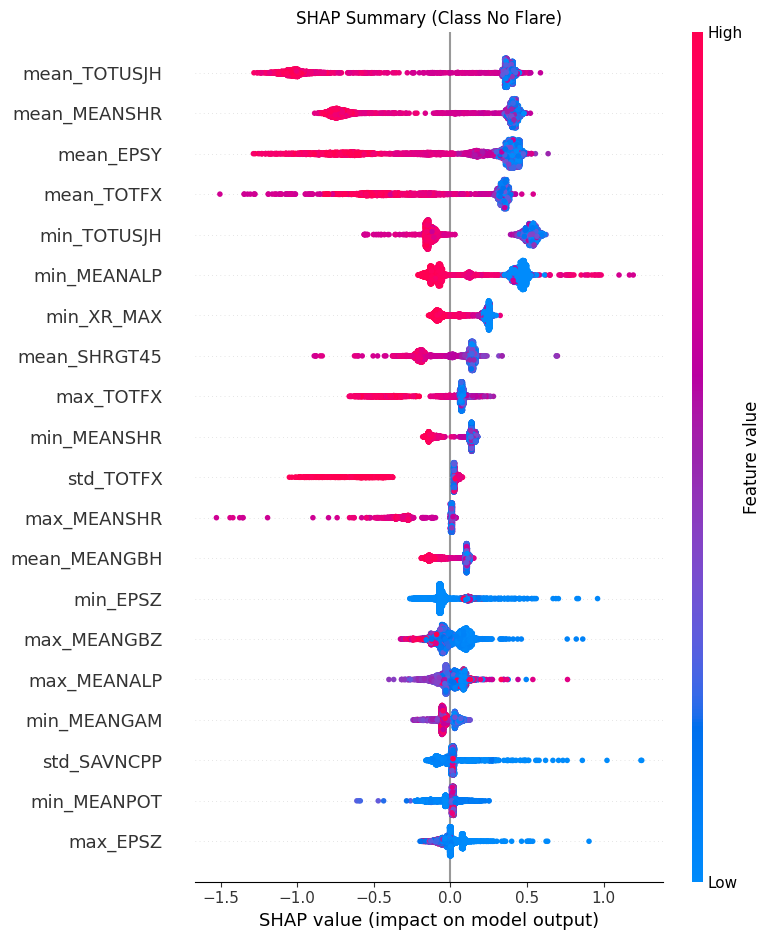

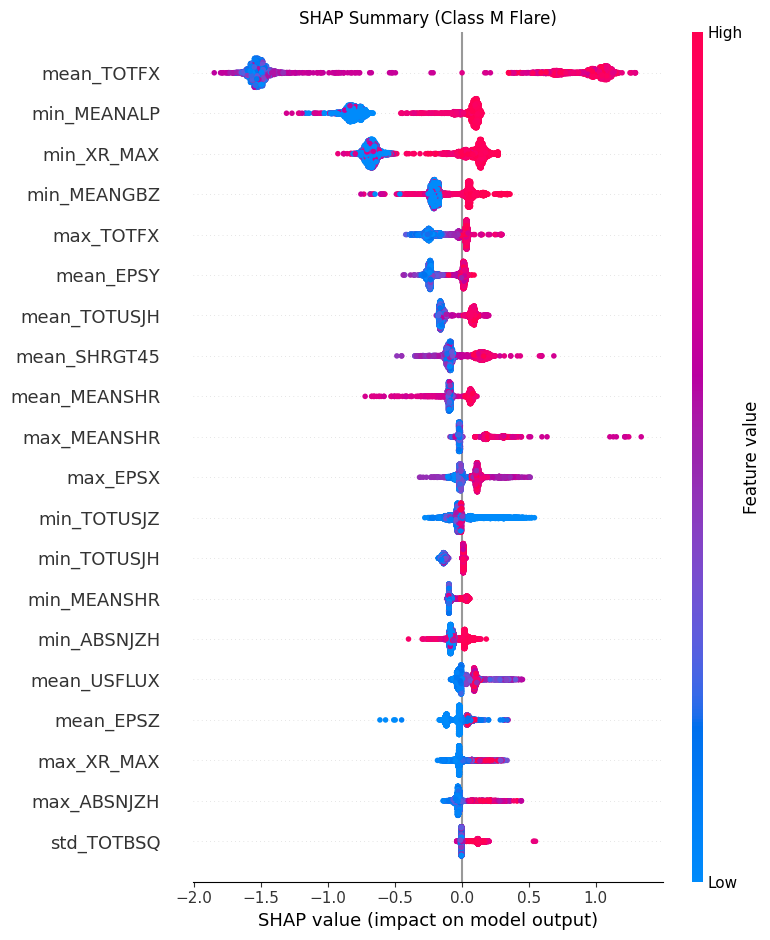

In [ ]:
# X_train_xgb: (N, D) features you trained on
# model: fitted XGBClassifier

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_train_xgb)  # multiclass: list of arrays, one per class

# Option A: one plot per class
class_names = ["No Flare", "M Flare", "X Flare"]
for k in range(3):
    plt.figure(figsize=(7, 5))
    shap.summary_plot(shap_values[k], X_train_xgb, feature_names=feature_names, show=False)
    plt.title(f"SHAP Summary (Class {class_names[k]})")
    plt.tight_layout()
    plt.show()

# Option B: aggregate multiclass importance into one ranking (mean |SHAP| across classes)
shap_abs = np.mean([np.abs(sv) for sv in shap_values], axis=0)  # (N, D)
mean_abs = shap_abs.mean(axis=0)                                # (D,)
top_idx = np.argsort(mean_abs)[::-1][:25]

plt.figure(figsize=(7, 5))
plt.barh([feature_names[i] for i in top_idx][::-1], mean_abs[top_idx][::-1])
plt.xlabel("Mean |SHAP value| (avg over classes)")
plt.title("Global Feature Importance (SHAP)")
plt.tight_layout()
plt.show()

In [ ]:
featam = 20
#calculate variance


In [ ]:
X_train_df = pd.DataFrame(X_train_xgb, columns=feature_names)
X_val_df   = pd.DataFrame(X_val_xgb,   columns=feature_names)

In [ ]:
def train_with_top_k(k, ranking, y_value):
    top_feats = ranking.iloc[:k].tolist()   # take the first k feature names

    model_k = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42
    )

    model_k.fit(X_train_df[top_feats], Y_train)

    y_prob = model_k.predict_proba(X_val_df[top_feats])[:, y_value]
    y_true_binary = (Y_val == y_value).astype(int)

    fpr, tpr, _ = roc_curve(y_true_binary, y_prob)
    auc_k = auc(fpr, tpr)
    return fpr, tpr, auc_k


In [ ]:
shaprankseries = pd.Series(shaprank)
flareclass = 1
fpr_20, tpr_20, auc_20 = train_with_top_k(20, shaprankseries, flareclass)
fpr_10, tpr_10, auc_10 = train_with_top_k(10, shaprankseries, flareclass)
fpr_5, tpr_5, auc_5 = train_with_top_k(5, shaprankseries, flareclass)

In [ ]:
plt.figure()

#plt.plot(fpr_full, tpr_full, label=f'All features (AUC={auc_full:.3f})')
plt.plot(fpr_20, tpr_20, label=f'Top 20 (AUC={auc_20:.3f})')
plt.plot(fpr_10, tpr_10, label=f'Top 10 (AUC={auc_10:.3f})')
plt.plot(fpr_5, tpr_5, label=f'Top 5 (AUC={auc_5:.3f})')

plt.plot([0,1],[0,1],'k--', label='Chance')

plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.legend()
plt.title('Feature Ablation ROC Comparison for Class = ' + str(flareclass))
plt.show()


In [ ]:
def per_class_roc_auc(y_true, y_prob):
    y_bin = label_binarize(y_true, classes=[0, 1, 2])
    out = []
    for c in range(3):
        out.append(roc_auc_score(y_bin[:, c], y_prob[:, c]))
    return np.array(out)

def per_class_pr_auc(y_true, y_prob):
    y_bin = label_binarize(y_true, classes=[0, 1, 2])
    out = []
    for c in range(3):
        out.append(average_precision_score(y_bin[:, c], y_prob[:, c]))
    return np.array(out)


In [ ]:
ks = [5, 10, 15, 20, 30, 50, 75, 100, 125]

Z = []  # will become shape (len(ks), 3)

for k in ks:
    top_feats = rank_gain.index[:k]

    model_k = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42
    )

    model_k.fit(X_train_df[top_feats], Y_train)
    y_prob = model_k.predict_proba(X_val_df[top_feats])

    # choose one metric
    Z.append(per_class_roc_auc(Y_val, y_prob))   # or per_class_pr_auc

Z = np.array(Z)  # (len(ks), 3)
print(Z.shape)

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401


K_grid, C_grid = np.meshgrid(ks, [0, 1, 2], indexing="xy")
Z_grid = Z.T  # now shape (3, len(ks)) aligns with meshgrid

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    K_grid, C_grid, Z_grid,
    cmap="viridis",
    edgecolor="k",
    linewidth=0.3,
    antialiased=True
)

ax.set_xlabel("Number of features (k)")
ax.set_ylabel("Class")
ax.set_zlabel("Metric value")
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["No Flare", "M Flare", "X Flare"])
ax.set_title("3D Feature Ablation Surface (OvR per class)")

fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.1, label="Metric value")
plt.tight_layout()
plt.show()

In [ ]:
import joblib

joblib.dump(model, "xgb_model.pkl")
np.save("X_cls.npy", X_val_xgb[[1,2553,1469], :])
np.save("y_cls.npy", Y_val[[1,2553,1469]])

In [ ]:
X[1011,0,-1]

In [ ]:
idx = np.where((X[:, 0, -1] == 0.00001962) & (X[:, 1, -1] == 0.000015993) & (X[:, 2, -1] == 0.000011696))[0]
idx

In [ ]:
X[88, :, -1] == X[1252, :, -1]

In [ ]:
X[0, :, :]